# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [45]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [46]:

df = pd.read_csv("AviationData_cleaned.csv")

df.head()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18968\478743228.py:1: DtypeWarning: Columns (0: Event.Id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("AviationData_cleaned.csv")


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Total.People,Fatal.Serious.Injuries,Fatal.Serious.Injury.Rate,Aircraft.Destroyed,Plane.Type
0,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,IMC,Probable Cause,02-05-2011,2.0,2.0,1.0,1,PIPER PA-28-140
1,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,0.0,4.0,VMC,Probable Cause,17-10-2016,5.0,1.0,0.2,0,DE HAVILLAND DHC-6
2,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,0.0,1.0,VMC,Probable Cause,05-05-2011,1.0,0.0,0.0,0,BEECH C35
3,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,0.0,1.0,VMC,Probable Cause,01-02-2016,1.0,0.0,0.0,0,CESSNA 180K
4,20001214X38957,Accident,ATL84LA120,1984-03-14,"MYRTLE BEACH, SC",United States,NaN,NaN,CRE,GRAND STRAND,...,0.0,1.0,VMC,Probable Cause,24-09-2018,1.0,0.0,0.0,0,BEECH 99


In [47]:
df.shape

(16539, 33)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [48]:
# Separate aircraft into smaller and larger airplanes
df["Aircraft.Size"] = df["Total.People"].apply(
    lambda x: "Small" if x < 20 else "Large"
)

# Check the number of accidents in each group
df["Aircraft.Size"].value_counts()

Aircraft.Size
Small    16073
Large      466
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [49]:
# Calculate the mean fatal/serious injury fraction for each Make
# separately for Small and Large aircraft

make_safety = (
    df.groupby(["Aircraft.Size", "Make"])["Fatal.Serious.Injury.Rate"]
      .mean()
      .reset_index()
)

# Get the 15 Makes with the lowest mean injury rate for each group
small_makes = (
    make_safety[make_safety["Aircraft.Size"] == "Small"]
    .sort_values("Fatal.Serious.Injury.Rate")
    .head(15)
)

large_makes = (
    make_safety[make_safety["Aircraft.Size"] == "Large"]
    .sort_values("Fatal.Serious.Injury.Rate")
    .head(15)
)

# Display the results
print("Small aircraft - 15 lowest-risk Makes:")
display(small_makes)

print("Large aircraft - 15 lowest-risk Makes:")
display(large_makes)

Small aircraft - 15 lowest-risk Makes:


,Aircraft.Size,Make,Fatal.Serious.Injury.Rate
33,Small,MCDONNELL DOUGLAS,0.141071
15,Small,AVIAT AIRCRAFT INC,0.164474
32,Small,MAULE,0.164806
19,Small,BOEING,0.189450
30,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,0.206897
16,Small,AYRES,0.215686
40,Small,STINSON,0.216408
14,Small,AVIAT,0.224638
18,Small,BELLANCA,0.224654
9,Small,AERONCA,0.225833


Large aircraft - 15 lowest-risk Makes:


,Aircraft.Size,Make,Fatal.Serious.Injury.Rate
4,Large,DEHAVILLAND,0.000000
6,Large,MCDONNELL DOUGLAS,0.010917
2,Large,BOEING,0.099316
5,Large,EMBRAER,0.099474
0,Large,AIRBUS,0.143900
7,Large,RAYTHEON AIRCRAFT COMPANY,0.150000
3,Large,DE HAVILLAND,0.289526
1,Large,BEECH,1.000000


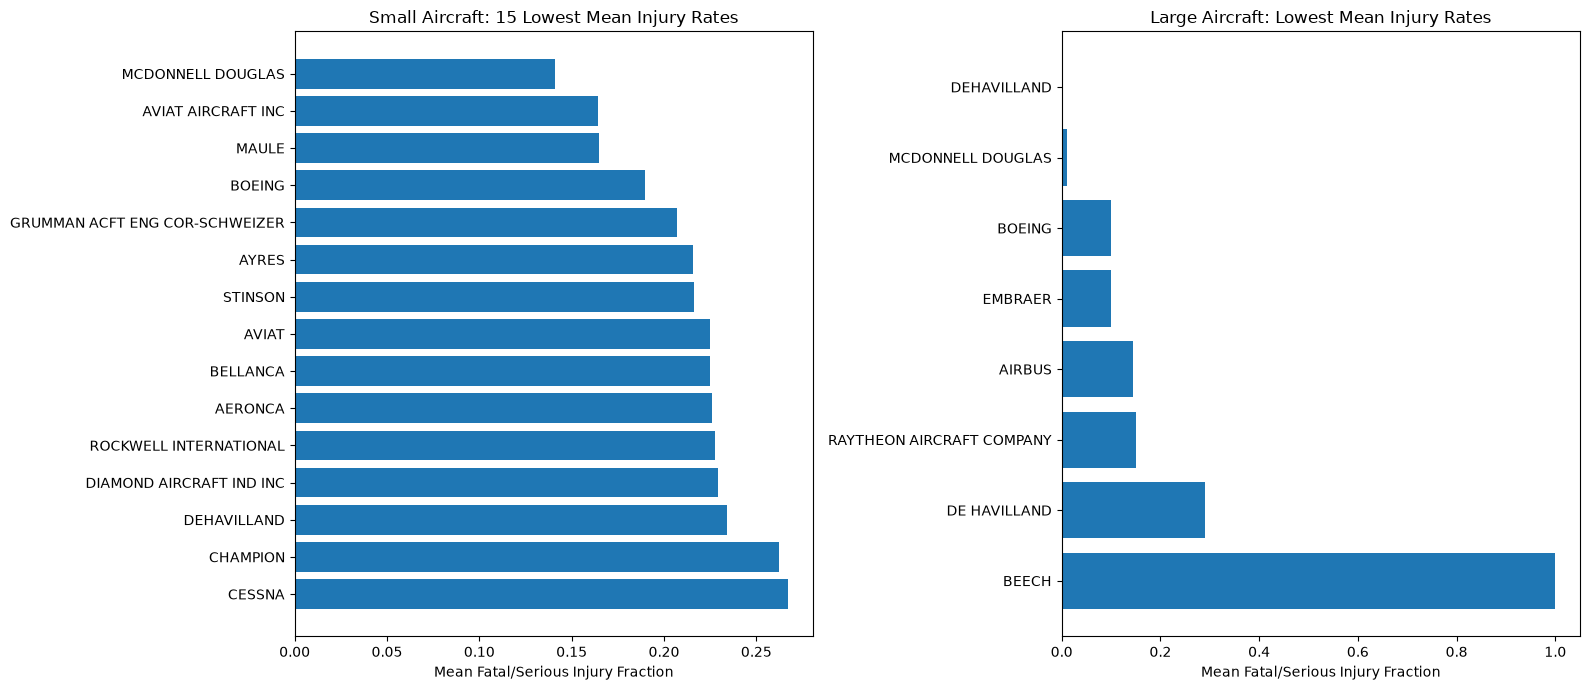

In [50]:

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Small aircraft
axes[0].barh(
    small_makes["Make"],
    small_makes["Fatal.Serious.Injury.Rate"]
)
axes[0].set_title("Small Aircraft: 15 Lowest Mean Injury Rates")
axes[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[0].invert_yaxis()

# Large aircraft
axes[1].barh(
    large_makes["Make"],
    large_makes["Fatal.Serious.Injury.Rate"]
)
axes[1].set_title("Large Aircraft: Lowest Mean Injury Rates")
axes[1].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

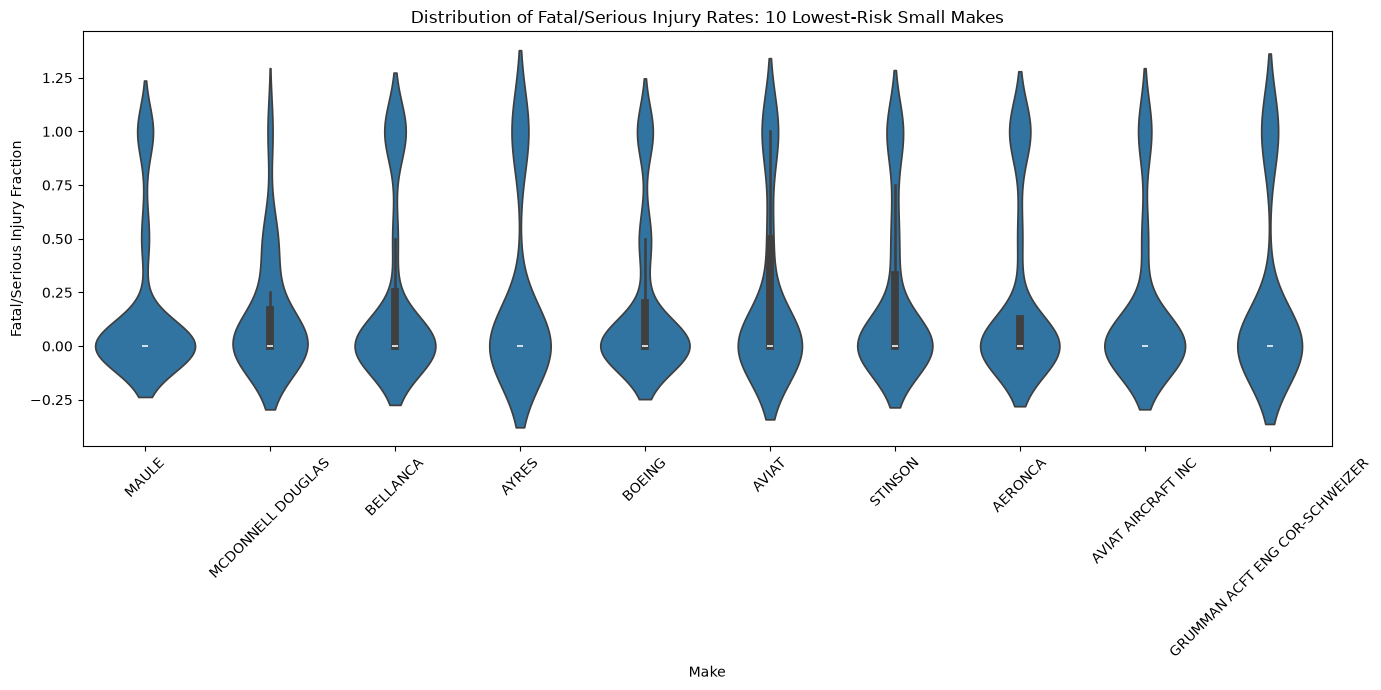

In [51]:

# Get the 10 small makes with the lowest mean injury rates
top_10_small_makes = (
    make_safety[make_safety["Aircraft.Size"] == "Small"]
    .sort_values("Fatal.Serious.Injury.Rate")
    .head(10)
)

# Keep only those makes in the original data
small_make_data = df[
    (df["Aircraft.Size"] == "Small") &
    (df["Make"].isin(top_10_small_makes["Make"]))
]

# Violin plot
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_make_data,
    x="Make",
    y="Fatal.Serious.Injury.Rate"
)

plt.title("Distribution of Fatal/Serious Injury Rates: 10 Lowest-Risk Small Makes")
plt.xlabel("Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

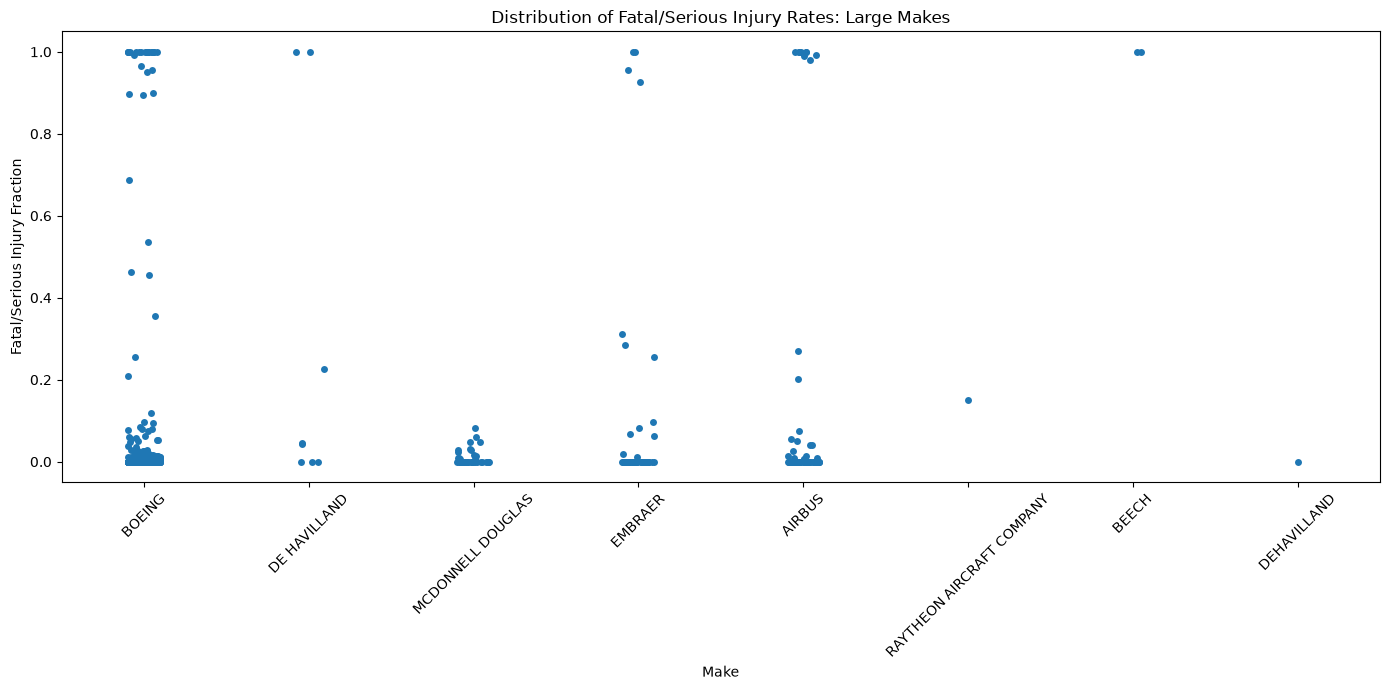

In [52]:

# Get the 10 large makes with the lowest mean injury rates
top_10_large_makes = (
    make_safety[make_safety["Aircraft.Size"] == "Large"]
    .sort_values("Fatal.Serious.Injury.Rate")
    .head(10)
)

# Keep only those makes in the original data
large_make_data = df[
    (df["Aircraft.Size"] == "Large") &
    (df["Make"].isin(top_10_large_makes["Make"]))
]

# Strip plot
plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_make_data,
    x="Make",
    y="Fatal.Serious.Injury.Rate"
)

plt.title("Distribution of Fatal/Serious Injury Rates: Large Makes")
plt.xlabel("Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [53]:
# Calculate destruction rate by aircraft size and make
destruction_by_make = (
    df.groupby(["Aircraft.Size", "Make"])["Aircraft.Destroyed"]
      .mean()
      .reset_index()
)

# Lowest 15 small makes
lowest_15_small_destruction = (
    destruction_by_make[destruction_by_make["Aircraft.Size"] == "Small"]
    .sort_values("Aircraft.Destroyed")
    .head(15)
)

# Lowest 15 large makes
lowest_15_large_destruction = (
    destruction_by_make[destruction_by_make["Aircraft.Size"] == "Large"]
    .sort_values("Aircraft.Destroyed")
    .head(15)
)

print("Small aircraft - 15 lowest destruction rates:")
display(lowest_15_small_destruction)

print("Large aircraft - 15 lowest destruction rates:")
display(lowest_15_large_destruction)

Small aircraft - 15 lowest destruction rates:


,Aircraft.Size,Make,Aircraft.Destroyed
31,Small,LUSCOMBE,0.014184
30,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241
40,Small,STINSON,0.023256
41,Small,TAYLORCRAFT,0.032258
9,Small,AERONCA,0.035000
28,Small,ERCOUPE,0.038462
13,Small,AMERICAN CHAMPION AIRCRAFT,0.039216
15,Small,AVIAT AIRCRAFT INC,0.039474
32,Small,MAULE,0.041860
25,Small,DEHAVILLAND,0.043478


Large aircraft - 15 lowest destruction rates:


,Aircraft.Size,Make,Aircraft.Destroyed
7,Large,RAYTHEON AIRCRAFT COMPANY,0.000000
4,Large,DEHAVILLAND,0.000000
5,Large,EMBRAER,0.078431
2,Large,BOEING,0.090909
6,Large,MCDONNELL DOUGLAS,0.105263
0,Large,AIRBUS,0.132353
3,Large,DE HAVILLAND,0.250000
1,Large,BEECH,1.000000


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [54]:
# Count accident records for each large plane type
large_plane_counts = (
    df[df["Aircraft.Size"] == "Large"]["Plane.Type"]
    .value_counts()
)

# Keep plane types with at least 10 accident records
valid_large_plane_types = large_plane_counts[
    large_plane_counts >= 10
].index

# Filter the data
large_plane_df = df[
    (df["Aircraft.Size"] == "Large") &
    (df["Plane.Type"].isin(valid_large_plane_types))
].copy()

# Calculate mean fatal/serious injury fraction
large_plane_safety = (
    large_plane_df
    .groupby("Plane.Type")["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
    .sort_values("Fatal.Serious.Injury.Rate")
)

display(large_plane_safety)

,Plane.Type,Fatal.Serious.Injury.Rate
5,BOEING 777,0.002258
3,BOEING 757,0.002651
6,EMBRAER EMB-145LR,0.015000
2,BOEING 737 7H4,0.079474
4,BOEING 767,0.080531
1,BOEING 737,0.173053
0,AIRBUS A320,0.273252


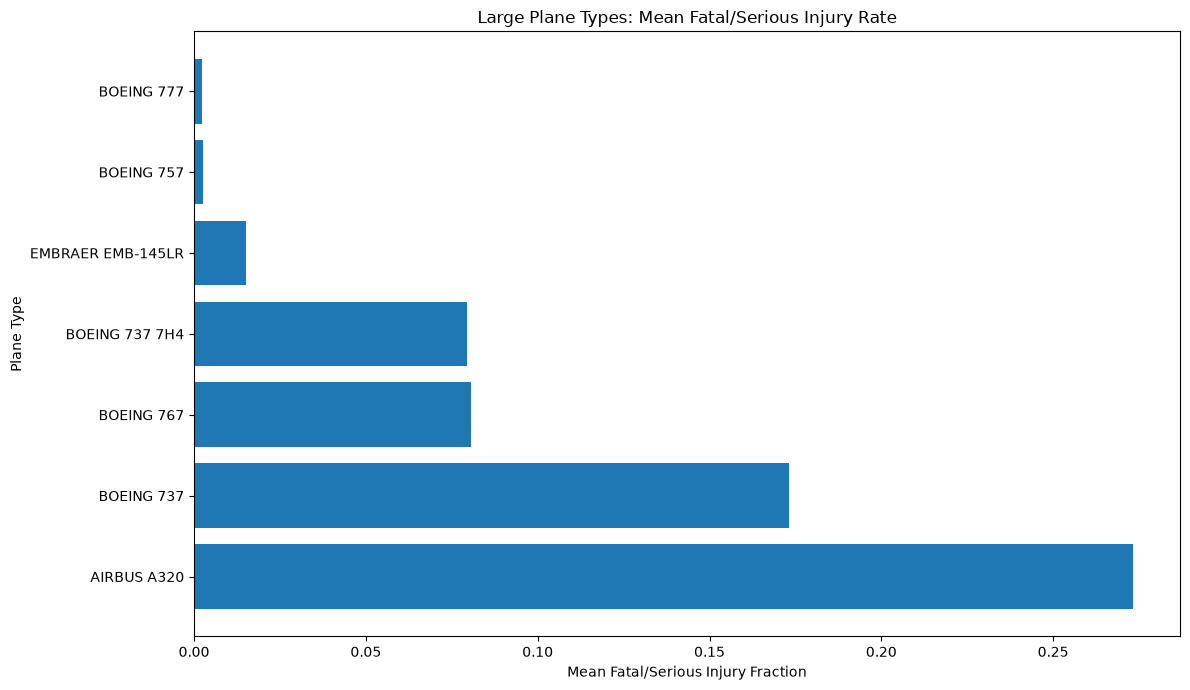

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    large_plane_safety["Plane.Type"],
    large_plane_safety["Fatal.Serious.Injury.Rate"]
)

plt.title("Large Plane Types: Mean Fatal/Serious Injury Rate")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Plane Type")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [56]:
# Count accident records for each small plane type
small_plane_counts = (
    df[df["Aircraft.Size"] == "Small"]["Plane.Type"]
    .value_counts()
)

# Keep plane types with at least 10 accident records
valid_small_plane_types = small_plane_counts[
    small_plane_counts >= 10
].index

# Filter the data
small_plane_df = df[
    (df["Aircraft.Size"] == "Small") &
    (df["Plane.Type"].isin(valid_small_plane_types))
].copy()

# Calculate mean fatal/serious injury fraction
small_plane_safety = (
    small_plane_df
    .groupby("Plane.Type")["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
    .sort_values("Fatal.Serious.Injury.Rate")
)

# Keep the 10 lowest mean injury rates
top_10_small_plane_types = small_plane_safety.head(10)

display(top_10_small_plane_types)

,Plane.Type,Fatal.Serious.Injury.Rate
107,CESSNA 172SP,0.000000
223,MAULE M-5-210C,0.000000
209,DIAMOND AIRCRAFT IND INC DA 20 C1,0.000000
115,CESSNA 180J,0.037037
169,CESSNA A185E,0.038889
263,PIPER PA-20,0.040000
7,AIR TRACTOR AT 602,0.041667
47,BEECH B19,0.041667
114,CESSNA 180H,0.049020
138,CESSNA 195,0.049550


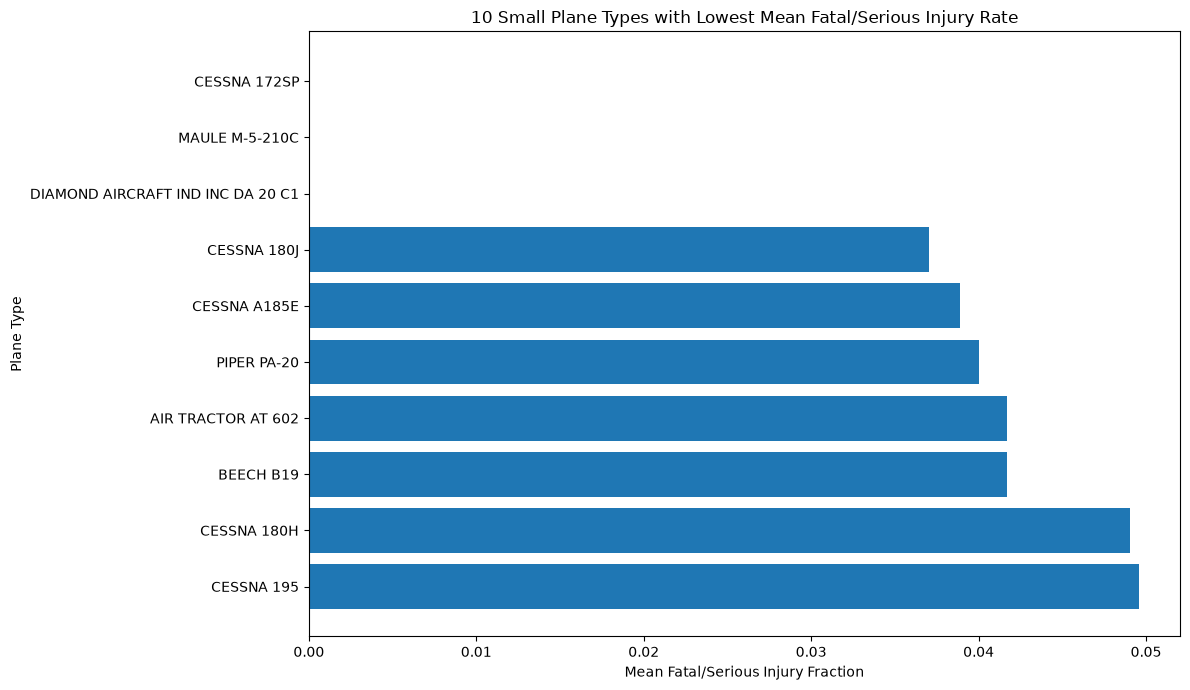

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_small_plane_types["Plane.Type"],
    top_10_small_plane_types["Fatal.Serious.Injury.Rate"]
)

plt.title("10 Small Plane Types with Lowest Mean Fatal/Serious Injury Rate")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Plane Type")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Airplane Types

For small airplanes, the CESSNA 172SP, MAULE M-5-210C, and DIAMOND AIRCRAFT IND INC DA 20 C1 had the lowest mean fatal/serious injury fraction of 0.000. Each had 11–12 accident records. For large airplanes, the BOEING 777 and BOEING 757 had the lowest mean fractions, at 0.0023 and 0.0027, respectively.

These results show differences in injury fractions across airplane types. However, some models have relatively few accident records, so the results should be interpreted cautiously. Low injury fractions in accident records do not necessarily mean a model is safest overall.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

### Factor 1: Weather Condition
First, let's calculate the two safety measures by weather condition:
- Mean fatal/serious injury fraction
- Aircraft destruction rate

In [58]:
weather_analysis = (
    df.groupby("Weather.Condition")
      .agg(
          Mean_Injury_Rate=("Fatal.Serious.Injury.Rate", "mean"),
          Aircraft_Destruction_Rate=("Aircraft.Destroyed", "mean"),
          Accident_Count=("Plane.Type", "count")
      )
      .reset_index()
)

weather_analysis

,Weather.Condition,Mean_Injury_Rate,Aircraft_Destruction_Rate,Accident_Count
0,IMC,0.647461,0.361653,871
1,UNK,0.541003,0.363158,190
2,VMC,0.237495,0.072349,13974


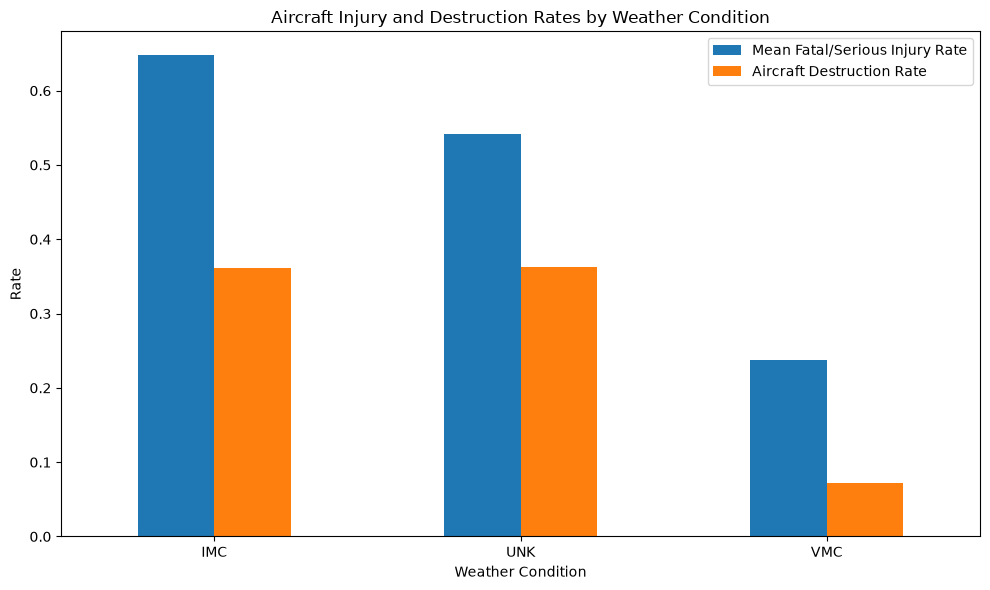

In [59]:


weather_plot = weather_analysis.set_index("Weather.Condition")[
    ["Mean_Injury_Rate", "Aircraft_Destruction_Rate"]
]

weather_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Aircraft Injury and Destruction Rates by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Rate")
plt.xticks(rotation=0)
plt.legend(
    ["Mean Fatal/Serious Injury Rate", "Aircraft Destruction Rate"]
)

plt.tight_layout()
plt.show()

### Discussion of Weather Condition

The results show that accidents occurring in **Instrument Meteorological Conditions (IMC)** had a higher mean fatal/serious injury rate (0.647) and aircraft destruction rate (0.362) than accidents in **Visual Meteorological Conditions (VMC)**, which had rates of 0.237 and 0.072, respectively. The unknown weather category (UNK) also had relatively high rates, but the actual weather conditions were not recorded. Most accident records occurred in VMC (13,974), compared with IMC (871) and UNK (190).

These results suggest that weather conditions may be associated with accident severity and aircraft damage. However, the data only includes accidents, so the results do not prove that weather caused these outcomes or show the overall risk of flying in each condition.

### Factor 2: Engine Type

First, let's calculate the two safety measures by engine type:

- Mean fatal/serious injury fraction
- Aircraft destruction rate

In [60]:

engine_analysis = (
    df.groupby("Engine.Type")
      .agg(
          Mean_Injury_Rate=("Fatal.Serious.Injury.Rate", "mean"),
          Aircraft_Destruction_Rate=("Aircraft.Destroyed", "mean"),
          Accident_Count=("Plane.Type", "count")
      )
      .reset_index()
)

engine_analysis.sort_values(
    "Mean_Injury_Rate"
)


,Engine.Type,Mean_Injury_Rate,Aircraft_Destruction_Rate,Accident_Count
4,Turbo Shaft,0.125000,0.000000,8
1,Turbo Fan,0.134666,0.096154,364
0,Reciprocating,0.255988,0.078916,12735
2,Turbo Jet,0.281937,0.244444,45
3,Turbo Prop,0.333008,0.192702,877
5,Unknown,0.440364,0.426471,68


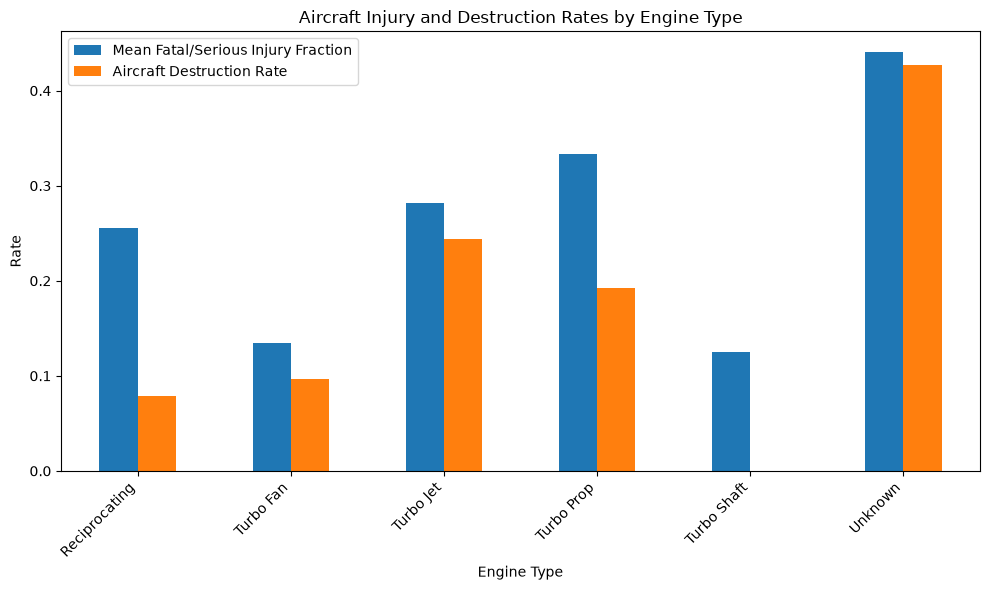

In [61]:


engine_plot = engine_analysis.set_index("Engine.Type")[
    ["Mean_Injury_Rate", "Aircraft_Destruction_Rate"]
]

engine_plot.plot(kind="bar", figsize=(10, 6))

plt.title("Aircraft Injury and Destruction Rates by Engine Type")
plt.xlabel("Engine Type")
plt.ylabel("Rate")
plt.xticks(rotation=45, ha="right")
plt.legend([
    "Mean Fatal/Serious Injury Fraction",
    "Aircraft Destruction Rate"
])
plt.tight_layout()
plt.show()


### Discussion of Engine Type

The results show that **Turbo Fan** engines had a relatively low mean fatal/serious injury fraction (0.135) and aircraft destruction rate (0.096), based on 364 accident records. Turbo Shaft engines had the lowest mean injury fraction (0.125) and a destruction rate of 0.000, but this was based on only 8 records. Turbo Jet and Turbo Prop engines had higher injury fractions and destruction rates. The Unknown category had the highest rates, but the engine type was not recorded.

Overall, Turbo Fan engines showed relatively low injury and destruction rates among the engine types with larger sample sizes. However, these results are based only on accident records, and differences in sample sizes mean they should be interpreted cautiously. They do not establish the overall safety of each engine type during normal operations.